In [1]:
# Load skincare products that have skin-type labels for KNN classification.
import pandas as pd
df = pd.read_csv("skincare_clean.csv")
labeled_df = df[df["has_skin_label"] == 1].copy()
skin_cols = ["tag_dry", "tag_oily", "tag_combination",
             "tag_normal", "tag_sensitive", "tag_acne_prone"]
print("Total Products:", len(df))
print("Labeled Products:", len(labeled_df))
print("Unlabeled Products:", len(df) - len(labeled_df))
print("\nSkin-Type Labels:")
print(labeled_df[skin_cols].sum())


Total Products: 2724
Labeled Products: 1557
Unlabeled Products: 1167

Skin-Type Labels:
tag_dry            1047.0
tag_oily            935.0
tag_combination    1209.0
tag_normal         1225.0
tag_sensitive       591.0
tag_acne_prone      397.0
dtype: float64


In [2]:
# Split labeled products into training and testing sets for KNN classification.
from sklearn.model_selection import train_test_split
X = labeled_df["ingredients_clean"]
y = labeled_df[skin_cols].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Products:", len(X_train))
print("Testing Products:", len(X_test))


Training Products: 1245
Testing Products: 312


In [3]:
# Convert training and testing ingredient lists into numerical TF-IDF features.
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_knn = TfidfVectorizer(token_pattern=r"[^|]+")
X_train_tfidf = tfidf_knn.fit_transform(X_train)
X_test_tfidf = tfidf_knn.transform(X_test)
print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)


Training Features: (1245, 4917)
Testing Features: (312, 4917)


In [4]:
# Train the KNN classifier to predict six skin-type labels.
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_tfidf, y_train)
print("KNN Model Trained Successfully!")
print("Number of Neighbors:", knn.n_neighbors)


KNN Model Trained Successfully!
Number of Neighbors: 5


In [5]:
# Predict skin-type labels for the testing products using KNN.
y_pred = knn.predict(X_test_tfidf)
print("Total Testing Products:", len(y_pred))
print("\nFirst 5 Predicted Labels:")
print(y_pred[:5])
print("\nFirst 5 Actual Labels:")
print(y_test.iloc[:5].values)


Total Testing Products: 312

First 5 Predicted Labels:
[[1 1 1 1 1 0]
 [0 0 0 0 0 1]
 [1 0 1 1 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 0 0]]

First 5 Actual Labels:
[[1 1 1 1 1 0]
 [0 0 0 0 0 1]
 [0 1 1 1 0 1]
 [0 0 1 0 0 0]
 [1 1 1 1 1 0]]


In [6]:
# Calculate the accuracy and F1 scores of our KNN classification model.
from sklearn.metrics import accuracy_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
micro_f1 = f1_score(y_test, y_pred, average="micro", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print("Exact Match Accuracy:", round(accuracy, 3))
print("Micro F1 Score:", round(micro_f1, 3))
print("Macro F1 Score:", round(macro_f1, 3))


Exact Match Accuracy: 0.272
Micro F1 Score: 0.761
Macro F1 Score: 0.715


In [7]:
# Display precision, recall, and F1 score for each skin type.
from sklearn.metrics import classification_report
print("KNN Classification Report:")
print(classification_report(  y_test, y_pred, target_names=skin_cols,zero_division=0))


KNN Classification Report:
                 precision    recall  f1-score   support

        tag_dry       0.76      0.86      0.81       201
       tag_oily       0.61      0.68      0.64       183
tag_combination       0.82      0.89      0.85       240
     tag_normal       0.79      0.92      0.85       239
  tag_sensitive       0.63      0.48      0.55       110
 tag_acne_prone       0.69      0.52      0.59        85

      micro avg       0.74      0.78      0.76      1058
      macro avg       0.72      0.72      0.72      1058
   weighted avg       0.74      0.78      0.75      1058
    samples avg       0.73      0.76      0.71      1058



In [8]:
# Create training and validation sets to find the best KNN neighbor value.
X_train_small, X_val, y_train_small, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
tfidf_val = TfidfVectorizer(token_pattern=r"[^|]+")
X_train_small_tfidf = tfidf_val.fit_transform(X_train_small)
X_val_tfidf = tfidf_val.transform(X_val)

print("Training Products:", len(X_train_small))
print("Validation Products:", len(X_val))


Training Products: 996
Validation Products: 249


In [9]:
# Test different K values and compare their validation F1 scores.
k_values = [1, 3, 5, 7, 9, 11, 15]
best_k = 1
best_score = 0
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_small_tfidf, y_train_small)

    predictions = model.predict(X_val_tfidf)

    score = f1_score(y_val, predictions, average="macro", zero_division=0)

    print("k =", k, "Macro F1 Score =", round(score, 3))

    if score > best_score:
        best_score = score
        best_k = k

print("\nBest K:", best_k)
print("Best Validation Macro F1:", round(best_score, 3))


k = 1 Macro F1 Score = 0.68
k = 3 Macro F1 Score = 0.699
k = 5 Macro F1 Score = 0.689
k = 7 Macro F1 Score = 0.695
k = 9 Macro F1 Score = 0.702
k = 11 Macro F1 Score = 0.698
k = 15 Macro F1 Score = 0.694

Best K: 9
Best Validation Macro F1: 0.702


In [10]:
# Train KNN with the best K value and evaluate it on the testing data.
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_tfidf, y_train)
y_pred_final = knn_final.predict(X_test_tfidf)
accuracy_final = accuracy_score(y_test, y_pred_final)
micro_f1_final = f1_score(y_test, y_pred_final, average="micro", zero_division=0)
macro_f1_final = f1_score(y_test, y_pred_final, average="macro", zero_division=0)
print("Selected K:", best_k)
print("Exact Match Accuracy:", round(accuracy_final, 3))
print("Micro F1 Score:", round(micro_f1_final, 3))
print("Macro F1 Score:", round(macro_f1_final, 3))


Selected K: 9
Exact Match Accuracy: 0.282
Micro F1 Score: 0.773
Macro F1 Score: 0.712


In [11]:
# Display the final KNN classification report for all six skin types.
print("Final KNN Classification Report (k = 9):")

print(classification_report( y_test,y_pred_final, target_names=skin_cols, zero_division=0))


Final KNN Classification Report (k = 9):
                 precision    recall  f1-score   support

        tag_dry       0.76      0.88      0.81       201
       tag_oily       0.66      0.74      0.70       183
tag_combination       0.81      0.92      0.86       240
     tag_normal       0.79      0.95      0.86       239
  tag_sensitive       0.67      0.46      0.55       110
 tag_acne_prone       0.64      0.40      0.49        85

      micro avg       0.75      0.80      0.77      1058
      macro avg       0.72      0.73      0.71      1058
   weighted avg       0.74      0.80      0.76      1058
    samples avg       0.75      0.77      0.72      1058



In [12]:
# Display confusion matrices for sensitive and acne-prone skin predictions.
from sklearn.metrics import confusion_matrix
for skin in ["tag_sensitive", "tag_acne_prone"]:
    i = skin_cols.index(skin)

    cm = confusion_matrix(y_test.iloc[:, i],y_pred_final[:, i], labels=[0, 1])
    print("\n", skin)

    display(pd.DataFrame(cm,index=["Actual 0", "Actual 1"],columns=["Predicted 0", "Predicted 1"]))



 tag_sensitive


,Predicted 0,Predicted 1
Actual 0,177,25
Actual 1,59,51



 tag_acne_prone


,Predicted 0,Predicted 1
Actual 0,208,19
Actual 1,51,34


In [13]:
# Compare KNN with a simple baseline using the most common training labels.
baseline_pred = pd.DataFrame(index=y_test.index)
for skin in skin_cols:
    baseline_pred[skin] = y_train[skin].mode()[0]
print("Baseline Exact Match Accuracy:",
      round(accuracy_score(y_test, baseline_pred), 3))
print("Baseline Micro F1:",
      round(f1_score(y_test, baseline_pred, average="micro", zero_division=0), 3))
print("Baseline Macro F1:",
      round(f1_score(y_test, baseline_pred, average="macro", zero_division=0), 3))
print("\nKNN Macro F1:", round(macro_f1_final, 3))


Baseline Exact Match Accuracy: 0.067
Baseline Micro F1: 0.748
Baseline Macro F1: 0.543

KNN Macro F1: 0.712


In [14]:
# Train KNN on all labeled products and save the final model and TF-IDF vectorizer.
import joblib

tfidf_final = TfidfVectorizer(token_pattern=r"[^|]+")

X_all = tfidf_final.fit_transform(labeled_df["ingredients_clean"])

y_all = labeled_df[skin_cols].astype(int)

knn_deploy = KNeighborsClassifier(n_neighbors=best_k)

knn_deploy.fit(X_all, y_all)

joblib.dump(knn_deploy, "knn_skinmatch.pkl")
joblib.dump(tfidf_final, "tfidf_knn.pkl")

print("Final KNN Model Saved Successfully!")
print("TF-IDF Vectorizer Saved Successfully!")
print("Training Products:", len(labeled_df))
print("Selected K:", best_k)


Final KNN Model Saved Successfully!
TF-IDF Vectorizer Saved Successfully!
Training Products: 1557
Selected K: 9


In [15]:
# Predict skin-type labels for products that do not have existing labels.
unlabeled_df = df[df["has_skin_label"] == 0].copy()

X_unlabeled = tfidf_final.transform(unlabeled_df["ingredients_clean"])

predictions = knn_deploy.predict(X_unlabeled)

pred_cols = ["pred_" + skin for skin in skin_cols]

unlabeled_df[pred_cols] = predictions

print("Total Unlabeled Products:", len(unlabeled_df))
print("\nPredicted Skin-Type Counts:")
print(unlabeled_df[pred_cols].sum())

print("\nFirst 5 Products with Predictions:")
display(unlabeled_df[["brand", "name"] + pred_cols].head())


Total Unlabeled Products: 1167

Predicted Skin-Type Counts:
pred_tag_dry             920
pred_tag_oily            760
pred_tag_combination    1086
pred_tag_normal         1110
pred_tag_sensitive       230
pred_tag_acne_prone      113
dtype: int64

First 5 Products with Predictions:


,brand,name,pred_tag_dry,pred_tag_oily,pred_tag_combination,pred_tag_normal,pred_tag_sensitive,pred_tag_acne_prone
41,CeraVe,SA Cleanser Bar for Rough & Bumpy Skin,1,0,0,1,0,0
48,CeraVe,SA Cream for Rough & Bumpy Skin,1,0,0,1,0,0
63,CeraVe,SA Body Wash for Rough & Bumpy Skin,0,0,0,1,0,0
76,CeraVe,SA Lotion for Rough & Bumpy Skin,1,0,0,1,0,0
97,Algenist,Triple Algae Eye Renewal Balm Eye Cream,1,1,1,1,0,0


## Logistic Regression

**Hyperparameter tuning:** `C` controls regularisation (small C = simpler model that may underfit,
large C = more complex model that may overfit). It is tuned on the same validation set used for KNN's k.

In [16]:
# Tune C for Logistic Regression on the validation set (not the test set).
from sklearn.linear_model import LogisticRegression
import numpy as np

best_C, best_C_score = None, 0
for C in [0.01, 0.1, 0.5, 1, 2, 5, 10]:
    val_pred = np.column_stack([
        LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced", C=C)
        .fit(X_train_small_tfidf, y_train_small[skin]).predict(X_val_tfidf)
        for skin in skin_cols])
    score = f1_score(y_val, val_pred, average="macro", zero_division=0)
    print("C =", C, "Macro F1 Score =", round(score, 3))
    if score > best_C_score:
        best_C, best_C_score = C, score

print("\nBest C:", best_C)
print("Best Validation Macro F1:", round(best_C_score, 3))

C = 0.01 Macro F1 Score = 0.727
C = 0.1 Macro F1 Score = 0.729
C = 0.5 Macro F1 Score = 0.737
C = 1 Macro F1 Score = 0.742
C = 2 Macro F1 Score = 0.746
C = 5 Macro F1 Score = 0.744
C = 10 Macro F1 Score = 0.744

Best C: 2
Best Validation Macro F1: 0.746


In [17]:
# Train Logistic Regression: one model per skin type, with balanced class weights so that the rarer
# labels (sensitive, acne-prone) get more weight instead of being mostly predicted as "no".
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

lr_predictions = pd.DataFrame(index=y_test.index)
lr_models = {}

for skin in skin_cols:
    model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced", C=best_C)

    model.fit(X_train_tfidf, y_train[skin])

    lr_predictions[skin] = model.predict(X_test_tfidf)

    lr_models[skin] = model

    print(skin, "model trained successfully!")

print("\nLogistic Regression Results:")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Micro F1:", f1_score(y_test, lr_predictions, average="micro"))
print("Macro F1:", f1_score(y_test, lr_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=skin_cols,
    zero_division=0
))


tag_dry model trained successfully!
tag_oily model trained successfully!
tag_combination model trained successfully!
tag_normal model trained successfully!
tag_sensitive model trained successfully!
tag_acne_prone model trained successfully!

Logistic Regression Results:
Accuracy: 0.2916666666666667
Micro F1: 0.7553241836251775
Macro F1: 0.7279881355975434

Classification Report:
                 precision    recall  f1-score   support

        tag_dry       0.82      0.81      0.81       201
       tag_oily       0.67      0.66      0.67       183
tag_combination       0.82      0.79      0.81       240
     tag_normal       0.82      0.85      0.83       239
  tag_sensitive       0.60      0.60      0.60       110
 tag_acne_prone       0.63      0.67      0.65        85

      micro avg       0.76      0.75      0.76      1058
      macro avg       0.73      0.73      0.73      1058
   weighted avg       0.76      0.75      0.76      1058
    samples avg       0.75      0.75      0.71

In [18]:
# Save KNN and Logistic Regression comparison results
import pandas as pd
comparison = pd.DataFrame({
    "Model": ["KNN", "Logistic Regression"],

    "Accuracy": [
        accuracy_final,
        accuracy_score(y_test, lr_predictions)
    ],

    "Micro F1": [
        micro_f1_final,
        f1_score(y_test, lr_predictions, average="micro")
    ],

    "Macro F1": [
        macro_f1_final,
        f1_score(y_test, lr_predictions, average="macro")
    ]
})

comparison.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")
display(comparison)


Model comparison saved successfully!


,Model,Accuracy,Micro F1,Macro F1
0,KNN,0.282051,0.772748,0.712246
1,Logistic Regression,0.291667,0.755324,0.727988


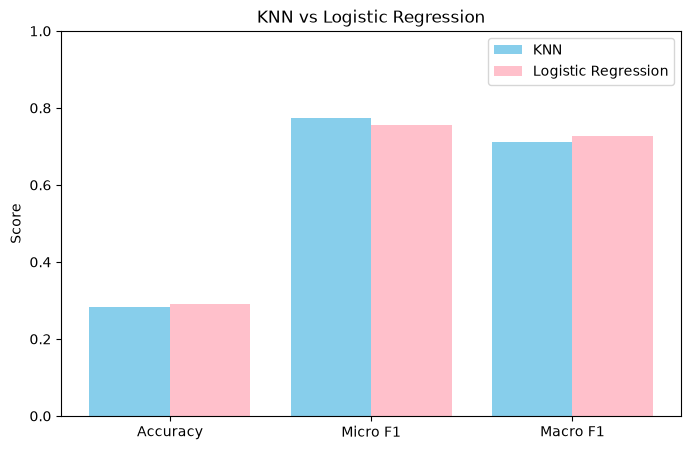

In [19]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Micro F1", "Macro F1"]

# Earlier KNN test results
knn_scores = [accuracy_final,micro_f1_final, macro_f1_final]

lr_scores = [
    accuracy_score(y_test, lr_predictions),
    f1_score(y_test, lr_predictions, average="micro"),
    f1_score(y_test, lr_predictions, average="macro")
]

x = range(len(metrics))

plt.figure(figsize=(8, 5))

plt.bar([i - 0.2 for i in x], knn_scores,
        width=0.4, label="KNN", color="skyblue")

plt.bar([i + 0.2 for i in x], lr_scores,
        width=0.4, label="Logistic Regression", color="pink")

plt.xticks(list(x), metrics)
plt.ylabel("Score")
plt.title("KNN vs Logistic Regression")
plt.ylim(0, 1)
plt.legend()
plt.show()


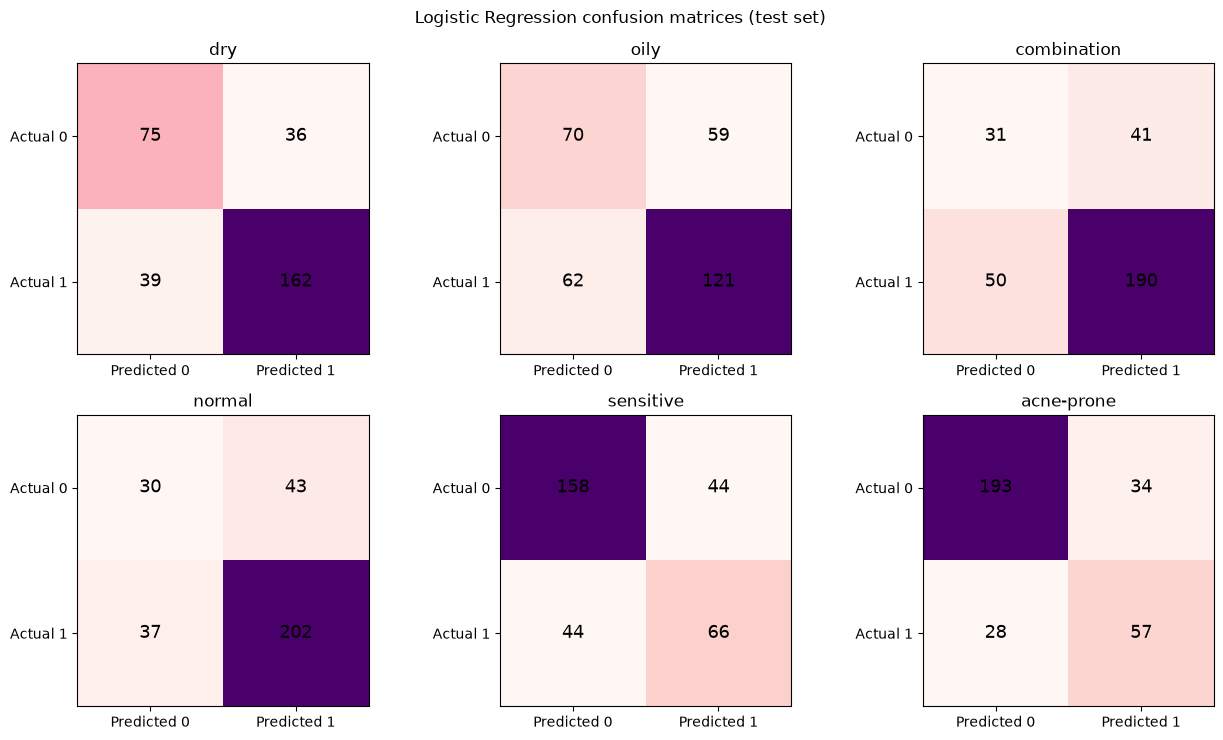

In [20]:
# Confusion matrices for Logistic Regression (all six skin types).
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, skin in zip(axes.ravel(), skin_cols):
    cm = confusion_matrix(y_test[skin], lr_predictions[skin], labels=[0, 1])
    ax.imshow(cm, cmap="RdPu")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=13)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Predicted 0", "Predicted 1"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Actual 0", "Actual 1"])
    ax.set_title(skin.replace("tag_", "").replace("_", "-"))
plt.suptitle("Logistic Regression confusion matrices (test set)")
plt.tight_layout()
plt.show()

## Model comparison: speed, overfitting and resource usage
Both final models (KNN with k = best_k, Logistic Regression with C = best_C) are trained again on the same
training data and measured on:
- **Training time** and **prediction time**,
- **Overfitting**: Macro F1 on the training data vs the unseen test data (a large gap means overfitting),
- **Resource usage**: size of the trained model in memory.

In [21]:
import time, pickle

class LRPerLabel:
    """Six Logistic Regression models (one per skin type) used together like one model."""
    def __init__(self, C):
        self.models = {s: LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced", C=C)
                       for s in skin_cols}
    def fit(self, X, y):
        for s in skin_cols:
            self.models[s].fit(X, y[s])
        return self
    def predict(self, X):
        return np.column_stack([self.models[s].predict(X) for s in skin_cols])

efficiency = []
for name, model in [(f"KNN (k={best_k})", KNeighborsClassifier(n_neighbors=best_k)),
                    (f"Logistic Regression (C={best_C})", LRPerLabel(best_C))]:
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    test_pred = np.asarray(model.predict(X_test_tfidf))
    predict_time = time.perf_counter() - start
    train_pred = np.asarray(model.predict(X_train_tfidf))

    train_f1 = f1_score(y_train, train_pred, average="macro", zero_division=0)
    test_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)
    efficiency.append({"Model": name,
                       "Training time (s)": round(train_time, 3),
                       "Prediction time, 312 products (s)": round(predict_time, 3),
                       "Train Macro F1": round(train_f1, 3),
                       "Test Macro F1": round(test_f1, 3),
                       "Gap (overfitting)": round(train_f1 - test_f1, 3),
                       "Model size (KB)": round(len(pickle.dumps(getattr(model, "models", model))) / 1024, 1)})
efficiency = pd.DataFrame(efficiency)
display(efficiency)
efficiency.to_csv("model_efficiency.csv", index=False)

,Model,Training time (s),"Prediction time, 312 products (s)",Train Macro F1,Test Macro F1,Gap (overfitting),Model size (KB)
0,KNN (k=9),0.008,0.027,0.766,0.712,0.054,547.7
1,Logistic Regression (C=2),0.245,0.004,0.943,0.728,0.215,232.4


,k,Train Macro F1,Validation Macro F1
0,1,0.999,0.680
1,3,0.851,0.699
2,5,0.794,0.689
3,9,0.763,0.702
4,15,0.720,0.694


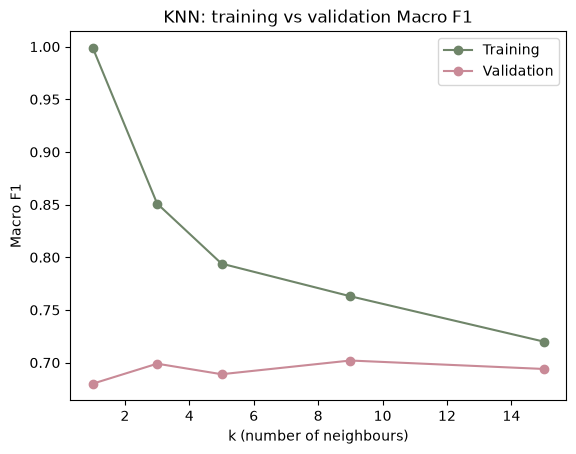

In [22]:
# Overfitting check for KNN across different k: training vs validation Macro F1.
rows = []
for k in [1, 3, 5, 9, 15]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_small_tfidf, y_train_small)
    rows.append({"k": k,
                 "Train Macro F1": round(f1_score(y_train_small, m.predict(X_train_small_tfidf), average="macro", zero_division=0), 3),
                 "Validation Macro F1": round(f1_score(y_val, m.predict(X_val_tfidf), average="macro", zero_division=0), 3)})
knn_curve = pd.DataFrame(rows)
display(knn_curve)
plt.plot(knn_curve["k"], knn_curve["Train Macro F1"], marker="o", label="Training", color="#6F8569")
plt.plot(knn_curve["k"], knn_curve["Validation Macro F1"], marker="o", label="Validation", color="#C98A97")
plt.title("KNN: training vs validation Macro F1")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Macro F1")
plt.legend()
plt.show()

In [23]:
import pandas as pd
import joblib
from sklearn.linear_model import LogisticRegression

# Load the original cleaned dataset
data = pd.read_csv("skincare_clean.csv")

# Select products with known skin-type labels
labeled = data[data["has_skin_label"] == 1].copy()

# Load the TF-IDF vectorizer trained on all labeled products
vectorizer = joblib.load("tfidf_knn.pkl")

# Prepare ingredient features
X_full = vectorizer.transform(
    labeled["ingredients_clean"].fillna("")
)

# Train six Logistic Regression models (balanced class weights)
lr_final_models = {}

for skin in skin_cols:
    model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced", C=best_C)

    model.fit(X_full, labeled[skin].astype(int))

    lr_final_models[skin] = model

    print(skin, "saved model trained!")

# Save all six models in one file
joblib.dump(lr_final_models, "logistic_regression.pkl")

print("\nLogistic Regression saved successfully!")


tag_dry saved model trained!
tag_oily saved model trained!
tag_combination saved model trained!
tag_normal saved model trained!
tag_sensitive saved model trained!
tag_acne_prone saved model trained!

Logistic Regression saved successfully!


In [24]:
import joblib
import pandas as pd

# Load saved models and vectorizer
saved_models = joblib.load("logistic_regression.pkl")
saved_vectorizer = joblib.load("tfidf_knn.pkl")

# Select 3 products for testing
sample = pd.read_csv("skincare_clean.csv").head(3)

# Convert ingredients into TF-IDF features
X_sample = saved_vectorizer.transform(
    sample["ingredients_clean"].fillna("")
)

# Predict all six skin-type labels
predictions = pd.DataFrame()

for skin in skin_cols:
    predictions[skin] = saved_models[skin].predict(X_sample)

# Display results
predictions.insert(0, "Product", sample["name"].values)

print("Logistic Regression loaded successfully!")
display(predictions)


Logistic Regression loaded successfully!


,Product,tag_dry,tag_oily,tag_combination,tag_normal,tag_sensitive,tag_acne_prone
0,Balancing & Clarifying Serum,1,1,1,1,1,1
1,GF 15% Solution,1,1,1,1,1,0
2,Multi-Antioxidant Radiance Serum,1,1,1,1,1,0


In [25]:
# Logistic Regression was selected (highest Macro F1 and much better acne-prone recall),
# so use it instead of KNN to predict skin types for the unlabeled products.
X_unlabeled = vectorizer.transform(unlabeled_df["ingredients_clean"].fillna(""))
for skin in skin_cols:
    unlabeled_df["pred_" + skin] = lr_final_models[skin].predict(X_unlabeled)

print("Predicted Skin-Type Counts (Logistic Regression):")
print(unlabeled_df[pred_cols].sum())

Predicted Skin-Type Counts (Logistic Regression):
pred_tag_dry             927
pred_tag_oily            624
pred_tag_combination     994
pred_tag_normal         1004
pred_tag_sensitive       443
pred_tag_acne_prone      112
dtype: int64


In [26]:
# Save all skincare products with separate Logistic Regression predictions for unlabeled products.
df_with_predictions = df.copy()
for col in pred_cols:
    df_with_predictions[col] = pd.NA

df_with_predictions.loc[unlabeled_df.index, pred_cols] = unlabeled_df[pred_cols]

df_with_predictions.to_csv("skincare_with_predictions.csv", index=False)

print("Dataset with Logistic Regression predictions saved successfully!")
print("Total Products:", len(df_with_predictions))
print("Original Labeled Products:", len(labeled_df))
print("Products with Logistic Regression Predictions:", len(unlabeled_df))


Dataset with Logistic Regression predictions saved successfully!
Total Products: 2724
Original Labeled Products: 1557
Products with Logistic Regression Predictions: 1167


### Conclusion

In this phase, KNN and Logistic Regression were used to predict six skin-type labels from skincare ingredients.

The dataset contained 1,557 labeled products and 1,167 unlabeled products. TF-IDF, fitted on the training data
only, converted ingredient lists into numerical features. Because the labels are imbalanced, **Macro F1** (every
skin type counts equally) was used as the main metric, alongside accuracy, precision, recall and confusion matrices.

**Hyperparameter tuning** was done on a separate validation set:
- KNN: k = 1, 3, 5, 7, 9, 11, 15 → best **k = 9** (validation Macro F1 0.702).
- Logistic Regression (one model per skin type, balanced class weights): C = 0.01 – 10 → best **C = 2**
  (validation Macro F1 0.746).

**Test results:**

| Metric | KNN (k = 9) | Logistic Regression (C = 2) |
|---|---|---|
| Exact Match Accuracy | 0.282 | **0.292** |
| Micro F1 | **0.772** | 0.755 |
| Macro F1 | 0.712 | **0.728** |
| F1 Sensitive | 0.55 | **0.60** |
| F1 Acne-prone | 0.49 | **0.65** |
| Recall Acne-prone | 0.40 | **0.67** |

**Speed, overfitting and resources:**

| | KNN (k = 9) | Logistic Regression (C = 2) |
|---|---|---|
| Training time | **0.002 s** | 0.08 s |
| Prediction time (312 products) | 0.006 s | **0.001 s** |
| Train / Test Macro F1 | 0.767 / 0.712 | 0.943 / 0.728 |
| Gap (overfitting) | **0.055** | 0.215 |
| Model size | 548 KB | **233 KB** |

- **Training speed:** KNN "trains" almost instantly because it only stores the training data; the real work
  happens at prediction time. Logistic Regression takes longer to train but predicts faster.
- **Overfitting:** Logistic Regression fits the training data much more closely than it fits the test data
  (gap 0.215), so it overfits more than KNN. KNN with k = 1 overfits strongly (train 0.999 vs validation 0.680),
  which is why a larger k was chosen. Despite its larger gap, Logistic Regression still performs **better on
  unseen data**, which is what matters for predicting new products.
- **Resources:** KNN must keep all training products in memory (548 KB, growing with more data), while
  Logistic Regression only stores one weight per ingredient per skin type (233 KB).

Logistic Regression achieved the highest Macro F1 and exact-match accuracy and found **67%** of acne-prone
products compared with 40% for KNN. KNN achieved a slightly higher Micro F1 because it predicts the common skin
types more often. Since suitable recommendations for sensitive and acne-prone skin are a key goal of SkinMatch,
**Logistic Regression was selected as the primary classification model**.

The six Logistic Regression models were retrained on all labeled products, saved in `logistic_regression.pkl`,
and used to predict skin-type labels for the 1,167 unlabeled products.

**Limitations:** the model predicts acne-prone for fewer unlabeled products (about 10%) than among labeled ones
(25%), so some acne-suitable products may still be missed. Predictions represent patterns in the dataset rather
than medically verified product suitability.